# Superstore: where does the profit go?

**Question:** the store sells almost $2.3M and makes a 12.5% margin. Which products, regions and pricing decisions create the profit, and which destroy it?

Data: 9,994 order lines of a US retailer (sample course data): segment, ship mode, region, state, city, category, sub-category, sales, quantity, discount, profit. There is no date or order id, so the analysis is about *where* and *at what price*, not *when*.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
NAVY, TEAL, AMBER, RED, GREY = "#14213D", "#2A9D8F", "#F4A259", "#D1495B", "#B8C0CC"
IMG = "../images/"
df = pd.read_csv("../data/superstore.csv")
df["margin"] = df.profit / df.sales
def summ(by):
    g = df.groupby(by).agg(orders=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
    g["margin_%"] = (g.profit / g.sales * 100).round(1)
    return g.round(0).astype({"orders": int})
print(df.shape); df.head()

(9994, 13)


,ship_mode,segment,city,state,postal_code,region,category,sub_category,sales,quantity,discount,profit,margin
0,Second Class,Consumer,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,0.1600
1,Second Class,Consumer,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820,0.3000
2,Second Class,Corporate,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,0.4700
3,Standard Class,Consumer,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310,-0.4000
4,Standard Class,Consumer,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,0.1125


## 1. The big picture

In [2]:
tot_s, tot_p = df.sales.sum(), df.profit.sum()
loss = df[df.profit < 0]
print(f"sales ${tot_s:,.0f}   profit ${tot_p:,.0f}   margin {tot_p/tot_s:.1%}")
print(f"loss-making order lines: {len(loss):,} of {len(df):,} ({len(loss)/len(df):.1%}); they lose ${-loss.profit.sum():,.0f}, which is {-loss.profit.sum()/df[df.profit>0].profit.sum():.0%} of all profit earned on the other lines")
display(summ("category").sort_values("profit"))

sales $2,297,201   profit $286,397   margin 12.5%
loss-making order lines: 1,871 of 9,994 (18.7%); they lose $156,131, which is 35% of all profit earned on the other lines


,orders,sales,profit,margin_%
category,,,,
Furniture,2121,742000.0,18451.0,2.0
Office Supplies,6026,719047.0,122491.0,17.0
Technology,1847,836154.0,145455.0,17.0


Technology and Office Supplies earn a 17% margin each. Furniture sells as much as the other two but keeps only 2%. The next sections find out why.

## 2. Sub-categories: three products lose money

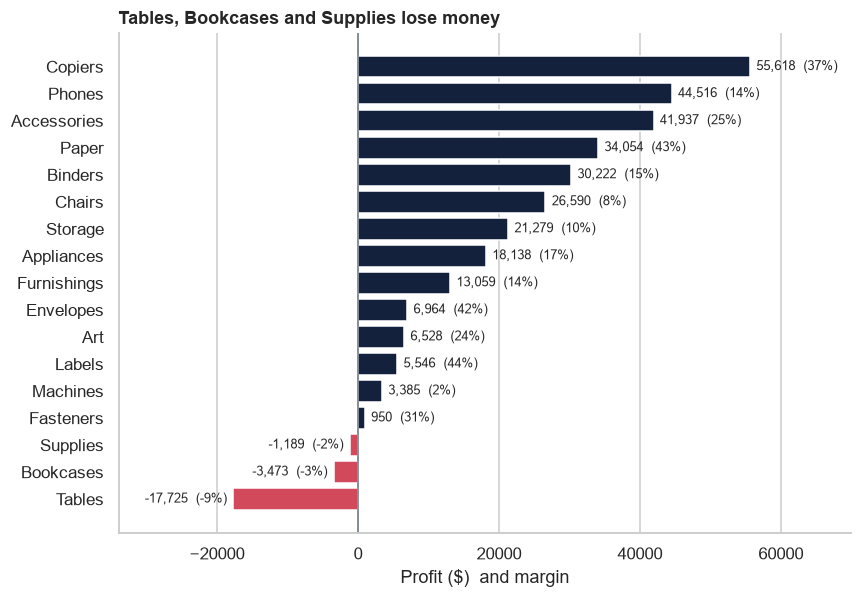

Tables alone: $-17,725 on $206,966 sales


In [3]:
sc = summ("sub_category").sort_values("profit")
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(sc.index, sc.profit, color=[RED if v < 0 else NAVY for v in sc.profit])
for y, (p, m) in enumerate(zip(sc.profit, sc["margin_%"])):
    ax.text(p + (900 if p >= 0 else -900), y, f"{p:,.0f}  ({m:.0f}%)", va="center", ha="left" if p >= 0 else "right", fontsize=8.5)
ax.axvline(0, color="#6B7785", lw=1); ax.set_xlim(-34000, 70000)
ax.set_title("Tables, Bookcases and Supplies lose money", loc="left", fontweight="bold"); ax.set_xlabel("Profit ($)  and margin"); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(IMG + "01_profit_by_subcategory.png", dpi=150); plt.show()
print("Tables alone:", f"${sc.loc['Tables','profit']:,.0f} on ${sc.loc['Tables','sales']:,.0f} sales")

## 3. Discounts are the root cause

Spearman correlation discount vs profit: -0.54 (p = 0.0e+00)   |   discount vs sales: -0.06


,order_lines,sales,profit,loss_making,margin_%
discount_band,,,,,
none,4798,1087908.0,320988.0,0.0,30.0
up to 10%,94,54369.0,9029.0,4.0,17.0
10-20%,3709,792153.0,91756.0,14.0,12.0
20-30%,227,103227.0,-10369.0,92.0,-10.0
30-40%,233,130911.0,-25448.0,89.0,-19.0
40-50%,77,64404.0,-23000.0,100.0,-36.0
over 50%,856,64229.0,-76559.0,100.0,-119.0


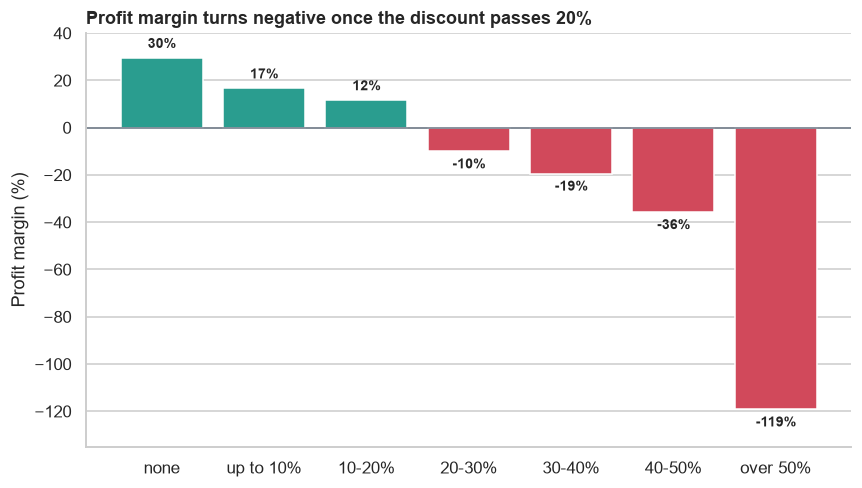

In [4]:
rho, p = stats.spearmanr(df.discount, df.profit)
print(f"Spearman correlation discount vs profit: {rho:.2f} (p = {p:.1e})   |   discount vs sales: {stats.spearmanr(df.discount, df.sales)[0]:.2f}")
bins = [-0.001, 0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.8]
labels = ["none", "up to 10%", "10-20%", "20-30%", "30-40%", "40-50%", "over 50%"]
df["discount_band"] = pd.cut(df.discount, bins=bins, labels=labels)
db = df.groupby("discount_band", observed=True).agg(order_lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"), loss_making=("profit", lambda s: (s < 0).mean()))
db["margin_%"] = (db.profit / db.sales * 100).round(1); db["loss_making"] = (db.loss_making * 100).round(0)
display(db.round(0))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.bar(db.index.astype(str), db["margin_%"], color=[TEAL if v > 0 else RED for v in db["margin_%"]])
for i, v in enumerate(db["margin_%"]):
    ax.text(i, v + (3 if v >= 0 else -3), f"{v:.0f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9, fontweight="bold")
ax.axhline(0, color="#6B7785", lw=1); ax.set_ylim(-135, 40)
ax.set_title("Profit margin turns negative once the discount passes 20%", loc="left", fontweight="bold"); ax.set_ylabel("Profit margin (%)"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(IMG + "02_margin_by_discount.png", dpi=150); plt.show()

There is no gentle trade-off: up to 20% the lines still earn a profit, above 20% almost every line loses money (89% to 100% of lines), and over 50% off the store loses more than it sells. Discount level is far more strongly linked to profit than to sales volume.

In [5]:
deep = df[df.discount > 0.20]
print(f"{len(deep):,} lines ({len(deep)/len(df):.1%} of lines, {deep.sales.sum()/tot_s:.1%} of sales) carry a discount above 20%")
print(f"they lose ${-deep.profit.sum():,.0f}; the other {len(df)-len(deep):,} lines earn ${df[df.discount <= 0.20].profit.sum():,.0f}")
# Illustration: same units sold, but the discount capped at 20%. Price effect only, volume assumed unchanged (an upper bound).
cost = deep.sales - deep.profit
list_price = deep.sales / (1 - deep.discount)
new_profit = list_price * 0.8 - cost
print(f"if those lines were sold at 20% off instead (same volume, an optimistic upper bound), their profit would be ${new_profit.sum():,.0f} instead of ${deep.profit.sum():,.0f}")
print(f"=> total profit ${tot_p - deep.profit.sum() + new_profit.sum():,.0f} vs ${tot_p:,.0f} today")
who = deep.groupby("sub_category").agg(lines=("sales", "size"), loss=("profit", "sum")).sort_values("loss")
display(who.round(0).head(6))

1,393 lines (13.9% of lines, 15.8% of sales) carry a discount above 20%
they lose $135,376; the other 8,601 lines earn $421,773
if those lines were sold at 20% off instead (same volume, an optimistic upper bound), their profit would be $83,815 instead of $-135,376
=> total profit $505,588 vs $286,397 today


,lines,loss
sub_category,,
Binders,613,-38510.0
Tables,176,-30698.0
Machines,53,-29555.0
Bookcases,70,-11098.0
Appliances,67,-8630.0
Chairs,158,-6737.0


## 4. Which products are discounted the hardest?

The discount effect is visible line by line, but **not** at sub-category level: Binders have the highest average discount (37%) and still make a profit overall. The damage comes from the *deep-discount lines inside* a sub-category (Binders, Tables and Machines lose the most there, see the table in section 3), not from the category average.

,avg_discount,deep_share,profit,margin
sub_category,,,,
Labels,7.0,0.0,5546.25,0.46
Storage,7.0,0.0,21278.83,0.09
Art,7.0,0.0,6527.79,0.27
Paper,7.0,0.0,34053.57,0.46
Supplies,8.0,0.0,-1189.10,0.11
Accessories,8.0,0.0,41936.64,0.21
Envelopes,8.0,0.0,6964.18,0.46
Fasteners,8.0,0.0,949.52,0.34
Furnishings,14.0,14.0,13059.14,0.28


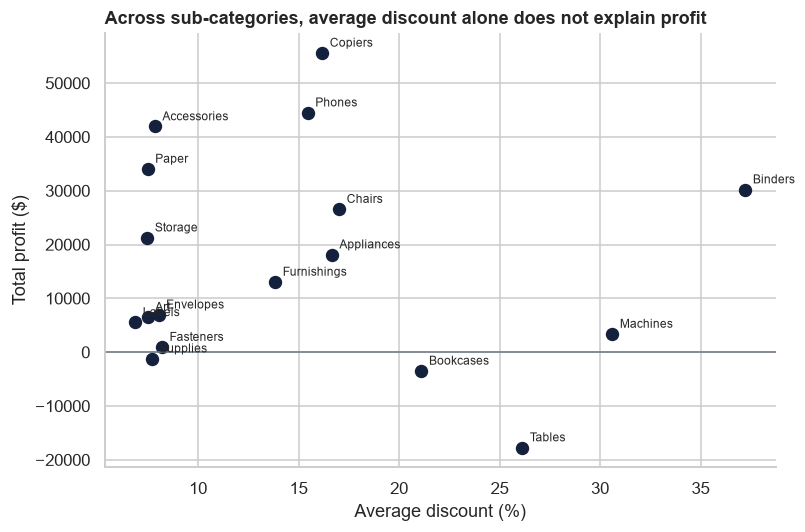

correlation of a sub-category's average discount with its total profit (17 points): -0.08 (no clear pattern)


In [6]:
dd = df.groupby("sub_category").agg(avg_discount=("discount", "mean"), deep_share=("discount", lambda s: (s > 0.2).mean()), profit=("profit", "sum"), margin=("margin", "median")).sort_values("avg_discount")
display((dd.assign(avg_discount=lambda x: (x.avg_discount * 100).round(0), deep_share=lambda x: (x.deep_share * 100).round(0)).round(2)))
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(dd.avg_discount * 100, dd.profit, s=60, color=NAVY)
for n, r in dd.iterrows():
    ax.annotate(n, (r.avg_discount * 100, r.profit), textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(0, color="#6B7785", lw=1)
ax.set_xlabel("Average discount (%)"); ax.set_ylabel("Total profit ($)")
ax.set_title("Across sub-categories, average discount alone does not explain profit", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(IMG + "03_discount_vs_profit_subcategory.png", dpi=150); plt.show()
print("correlation of a sub-category's average discount with its total profit (17 points):", round(dd.avg_discount.corr(dd.profit, method="spearman"), 2), "(no clear pattern)")

## 5. Geography

,orders,sales,profit,margin_%
region,,,,
Central,2323,501240.0,39706.0,8.0
South,1620,391722.0,46749.0,12.0
East,2848,678781.0,91523.0,14.0
West,3203,725458.0,108418.0,15.0


10 of 49 states lose money, in total $98,246


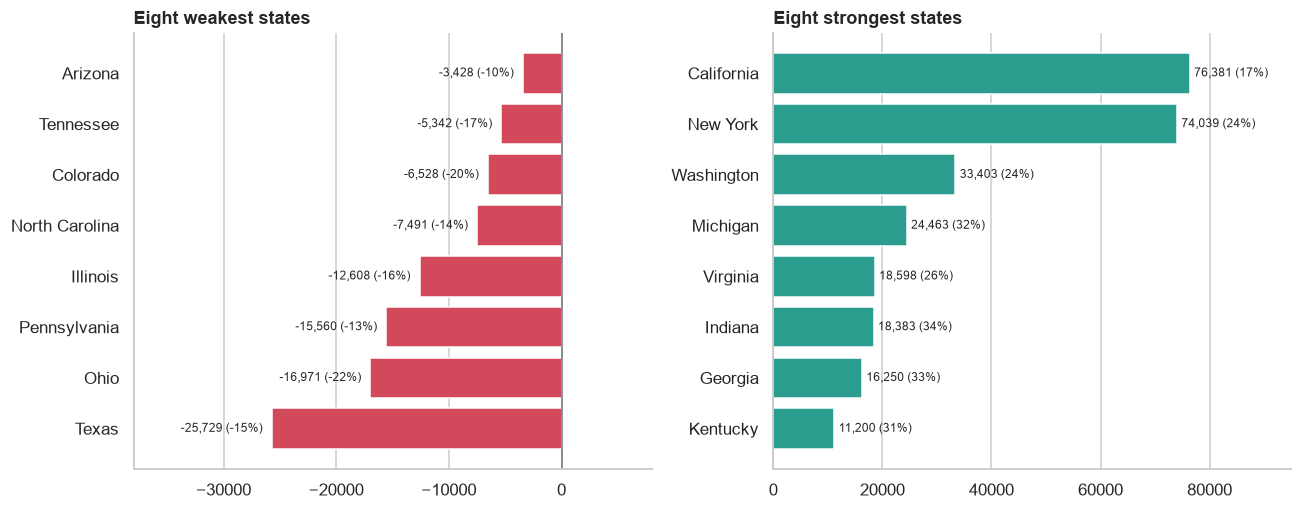

In [7]:
reg = summ("region").sort_values("profit")
display(reg)
st = summ("state").sort_values("profit")
neg = st[st.profit < 0]
print(f"{len(neg)} of {len(st)} states lose money, in total ${-neg.profit.sum():,.0f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
low, top = st.head(8), st.tail(8)
for ax, d, c, t in [(axes[0], low, RED, "Eight weakest states"), (axes[1], top, TEAL, "Eight strongest states")]:
    ax.barh(d.index, d.profit, color=c)
    for y, (p, m) in enumerate(zip(d.profit, d["margin_%"])):
        ax.text(p + (800 if p >= 0 else -800), y, f"{p:,.0f} ({m:.0f}%)", va="center", ha="left" if p >= 0 else "right", fontsize=8)
    ax.axvline(0, color="#6B7785", lw=1); ax.set_title(t, loc="left", fontweight="bold"); ax.grid(axis="y", visible=False)
axes[0].set_xlim(-38000, 8000); axes[1].set_xlim(0, 95000)
fig.tight_layout(); fig.savefig(IMG + "04_states.png", dpi=150); plt.show()

In [8]:
# Are the loss-making states simply the heavy-discount states?
s = df.groupby("state").agg(avg_discount=("discount", "mean"), profit=("profit", "sum"), sales=("sales", "sum"))
s["margin"] = s.profit / s.sales
print("states: correlation of average discount with margin:", round(s.avg_discount.corr(s.margin, method="spearman"), 2))
for name in ["Texas", "Ohio", "Pennsylvania", "Illinois"]:
    x = df[df.state == name]
    print(f"{name:13s} avg discount {x.discount.mean():.0%}  lines with >20% off: {(x.discount > .2).mean():.0%}   vs national {df.discount.mean():.0%} / {(df.discount > .2).mean():.0%}")

states: correlation of average discount with margin: -0.77
Texas         avg discount 37%  lines with >20% off: 42%   vs national 16% / 14%
Ohio          avg discount 32%  lines with >20% off: 38%   vs national 16% / 14%
Pennsylvania  avg discount 33%  lines with >20% off: 40%   vs national 16% / 14%
Illinois      avg discount 39%  lines with >20% off: 46%   vs national 16% / 14%


The weakest states (Texas, Ohio, Pennsylvania, Illinois) are the ones with the highest average discounts: the geography problem is a discount problem.

## 6. Segment and shipping

In [9]:
display(summ("segment").sort_values("profit")); display(summ("ship_mode").sort_values("profit"))
chi, p, *_ = stats.chi2_contingency(pd.crosstab(df.segment, df.profit < 0))
print(f"share of loss-making lines differs by segment? chi-square p = {p:.2f}")
kw = stats.kruskal(*[g.margin.values for _, g in df.groupby("ship_mode")])
print(f"margin differs by ship mode? Kruskal-Wallis p = {kw.pvalue:.2f}")

,orders,sales,profit,margin_%
segment,,,,
Home Office,1783,429653.0,60299.0,14.0
Corporate,3020,706146.0,91979.0,13.0
Consumer,5191,1161401.0,134119.0,12.0


,orders,sales,profit,margin_%
ship_mode,,,,
Same Day,543,128363.0,15892.0,12.0
First Class,1538,351428.0,48970.0,14.0
Second Class,1945,459194.0,57447.0,12.0
Standard Class,5968,1358216.0,164089.0,12.0


share of loss-making lines differs by segment? chi-square p = 0.20
margin differs by ship mode? Kruskal-Wallis p = 0.10


Segments and shipping modes have similar margins (12% to 14%): they are not where the money is lost.

## 7. Conclusions and recommendations

1. **Discounts above 20% are the main profit leak.** 14% of order lines (16% of sales) carry them and lose $135k, while the other 86% of lines earn $422k. Without the deep-discount losses profit would be 47% higher.
2. **Furniture is the problem category** (2% margin vs 17%), driven by Tables (-9%), Bookcases and by deep discounts; Technology and Office Supplies are healthy.
3. **Loss-making states are heavy-discount states** (Texas, Ohio, Pennsylvania, Illinois): fix discounting policy there before touching anything else.
4. **Segment and ship mode are not the issue.**

**Suggested actions:** cap discounts at 20% unless a manager approves; review the pricing of Tables and Bookcases; track margin, not only sales, in regional targets.

**Caveats:** sample data without dates or order ids; the 20% cap scenario assumes unchanged volume and is an upper bound; correlation between discount and loss is strong, but discounts may have been applied *because* items were not selling, so the data alone cannot prove the discount caused the loss.